# 07 · Measure before tuning

**Time:** 35–45 minutes. **Before this:** lessons 01–06.
**Requirements:** Python 3.11+, Jupyter, and `requirements-advanced.txt`.

You will measure completed work, individual response times, the slowest stage,
and two different views of memory. You will also see why a single timing can mislead.

All inputs are small and generated here. Sleeps simulate waiting only when
labeled. Timing assertions would be unreliable, so checks compare results instead.

[Course guide](README.md) · [Previous: DataLoader](06_pytorch_dataloader.ipynb) ·
[Next: Safe shared state](08_safe_shared_state.ipynb)

## 1. Ask a measurable question

Instead of asking whether threads are fast, ask: **For these eight jobs, how
does changing the worker count affect completed jobs per second and response time?**

- **Elapsed time:** how long the whole run takes on the clock.
- **Throughput:** completed jobs divided by elapsed time.
- **Latency:** time from submitting one job until that job finishes.
- **Queue wait:** time from submission until a worker starts the job.
- **Service time:** time spent inside the worker, from starting to finishing the job.

Latency includes queue wait. A function taking 30 milliseconds does not mean
every caller receives a result in 30 milliseconds when workers are busy.

In [1]:
import cProfile
import gc
import io
import os
from pathlib import Path
import pstats
import statistics
from tempfile import TemporaryDirectory
from time import perf_counter, process_time, sleep
import tracemalloc
from concurrent.futures import ThreadPoolExecutor

import psutil  # Installed by requirements-advanced.txt.

print("Notebook process ID:", os.getpid())

Notebook process ID: 24136


## 2. Record when each job actually runs

These eight jobs simulate I/O by sleeping. The worker records its own finish
time, rather than using the time when the caller eventually reads its future.
`perf_counter()` is a clock for elapsed time. Subtract a start reading from an
end reading to measure a duration; the raw reading is not a calendar time.

**Predict:** with two workers, will the last pair of jobs have longer latency
than the first pair, even though each job requests the same wait?

In [2]:
def measured_wait(job_id, submitted, delay):
    started = perf_counter()
    sleep(delay)  # Simulated blocking I/O, not a real download.
    finished = perf_counter()
    return {
        "id": job_id,
        "submitted": submitted,
        "started": started,
        "finished": finished,
        "queue_wait": started - submitted,
        "service_time": finished - started,
        "latency": finished - submitted,
    }

def measure_pool(workers, count=8, delay=0.025):
    started = perf_counter()
    with ThreadPoolExecutor(max_workers=workers) as pool:
        futures = []
        for job_id in range(count):
            submitted = perf_counter()
            futures.append(pool.submit(measured_wait, job_id, submitted, delay))
        rows = [future.result() for future in futures]
    elapsed = perf_counter() - started  # Includes pool creation and shutdown.
    assert [row["id"] for row in rows] == list(range(count))
    return elapsed, rows

In [3]:
elapsed, timeline_rows = measure_pool(workers=2)
print("id | queue wait ms | work ms | latency ms")
for row in timeline_rows:
    print(f"{row['id']:>2} | {row['queue_wait'] * 1000:>13.1f} | "
          f"{row['service_time'] * 1000:>7.1f} | {row['latency'] * 1000:>10.1f}")
print(f"Throughput: {len(timeline_rows) / elapsed:.1f} jobs/second")

id | queue wait ms | work ms | latency ms
 0 |           0.3 |    25.3 |       25.6
 1 |           0.1 |    25.2 |       25.4
 2 |          25.2 |    25.7 |       50.9
 3 |          25.2 |    25.8 |       51.0
 4 |          50.9 |    25.5 |       76.3
 5 |          50.9 |    25.6 |       76.5
 6 |          76.4 |    25.3 |      101.7
 7 |          76.5 |    25.3 |      101.8
Throughput: 77.9 jobs/second


Later jobs usually spend longer waiting for a worker. Their requested work
stays the same. Below, gray means waiting after submission and blue means
running inside a worker. The worker's blue interval mostly contains sleep.

This plot uses the measurements above. The drawing code is only presentation;
the timestamps and definitions are the parts to understand.

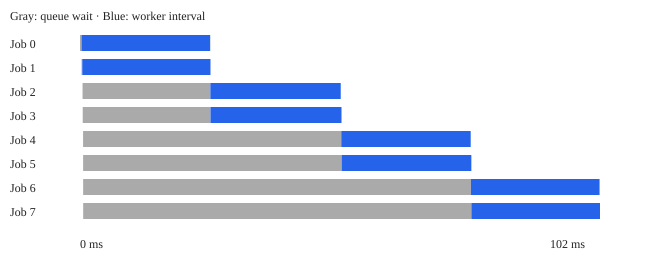

In [4]:
from IPython.display import SVG, display

origin = min(row["submitted"] for row in timeline_rows)
duration = max(row["finished"] for row in timeline_rows) - origin
scale = 520 / max(duration, 0.001)
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="660" height="260" '
         f'viewBox="0 0 660 260" role="img" aria-label="Measured job timeline">']
parts.append('<rect width="660" height="260" fill="white"/>')
parts.append('<text x="10" y="20" fill="#222">Gray: queue wait · Blue: worker interval</text>')
for index, row in enumerate(timeline_rows):
    y = 35 + index * 24
    left = 80 + (row["submitted"] - origin) * scale
    middle = 80 + (row["started"] - origin) * scale
    right = 80 + (row["finished"] - origin) * scale
    parts.append(f'<text x="10" y="{y + 13}" fill="#222">Job {row["id"]}</text>')
    parts.append(f'<rect x="{left}" y="{y}" width="{middle - left}" height="16" fill="#aaa"/>')
    parts.append(f'<rect x="{middle}" y="{y}" width="{right - middle}" height="16" fill="#2563eb"/>')
parts.append(f'<text x="80" y="248" fill="#222">0 ms</text>')
parts.append(f'<text x="550" y="248" fill="#222">{duration * 1000:.0f} ms</text></svg>')
display(SVG("".join(parts)))

## 3. Repeat a fair comparison

Keep the input count and delay constant. Change only the worker count.
Repeat each configuration three times and report the median, the middle
measurement. This reduces the influence of one unusually slow run.

A **wave** is one group of jobs that fits into the available workers. With eight
jobs and two workers, roughly four groups must take their turn.

**Predict:** which configurations will need eight, four, or two waves of waiting?

In [5]:
sweep = []
for workers in (1, 2, 4):
    elapsed_runs, latency_runs = [], []
    for _ in range(3):
        seconds, rows = measure_pool(workers)
        elapsed_runs.append(seconds)
        latency_runs.append(statistics.mean(row["latency"] for row in rows))
    seconds = statistics.median(elapsed_runs)
    sweep.append((workers, seconds, 8 / seconds, statistics.median(latency_runs)))

print("workers | median elapsed s | jobs/s | mean latency ms (median run summary)")
for workers, seconds, throughput, latency in sweep:
    print(f"{workers:>7} | {seconds:>16.3f} | {throughput:>6.1f} | {latency * 1000:>15.1f}")

workers | median elapsed s | jobs/s | mean latency ms (median run summary)
      1 |            0.204 |   39.2 |           114.5
      2 |            0.102 |   78.3 |            63.5
      4 |            0.052 |  153.0 |            38.2


Expect eight, four, and two waves. A real service may have connection limits or
a server **bottleneck**, a limit that holds back the overall completion rate.
Real disks have limited **bandwidth**, the amount of data they can transfer each second. This isolated sleep
experiment cannot select the best worker count for either.

Three trials are useful for this lesson, not a complete benchmark study. Tiny
timings are noisy. Longer jobs, more trials, varied ordering, and representative
inputs improve a serious comparison. Verify outputs before trusting speedups.

The eight pending futures are deliberately finite. The worker count alone
would not bound pending work if we kept submitting a huge input stream.

## 4. Elapsed time and CPU time answer different questions

`process_time()` counts CPU time used by this process, including its threads.
It excludes sleep and does not include CPU time from separate worker processes.
A process with several native CPU threads can accumulate more CPU time than
elapsed time. That is possible because several cores are doing work at once.

**Predict:** which clock will advance more during this sleep?
[Python timing reference](https://docs.python.org/3/library/time.html#time.process_time).

In [6]:
wall_start, cpu_start = perf_counter(), process_time()
sleep(0.06)
print(f"Elapsed: {perf_counter() - wall_start:.4f} s")
print(f"This process's CPU time: {process_time() - cpu_start:.4f} s")

Elapsed: 0.0606 s
This process's CPU time: 0.0000 s


## 5. Find the expensive stage

Here we really read small local files, then run Python arithmetic on their
bytes. This is a made-up preprocessing function for the lesson, not image decoding.
We time reading and transformation separately before adding any concurrency.

The operating system may cache these files in memory. These reads therefore
do not represent the speed of a large dataset on disk or remote storage.

In [7]:
def transform_bytes(data, rounds=40):
    score = 0
    for _ in range(rounds):
        for value in data:
            score += (value * value) % 97
    return score

def sequential_pipeline(paths):
    stage_seconds = {"read": 0.0, "transform": 0.0}
    results = []
    for path in paths:
        start = perf_counter()
        data = path.read_bytes()
        stage_seconds["read"] += perf_counter() - start
        start = perf_counter()
        results.append(transform_bytes(data))
        stage_seconds["transform"] += perf_counter() - start
    return results, stage_seconds

with TemporaryDirectory() as directory:
    paths = [Path(directory) / f"sample_{i}.bin" for i in range(6)]
    for index, path in enumerate(paths):
        path.write_bytes(bytes(range(256)) * 8)
    baseline, stage_seconds = sequential_pipeline(paths)
    for stage, seconds in stage_seconds.items():
        print(f"{stage:>9}: {seconds:.4f} s")
    assert len(baseline) == 6 and len(set(baseline)) == 1

    # Profile the same sequential functions while the temporary files exist.
    profiler = cProfile.Profile()
    profiled_results, _ = profiler.runcall(sequential_pipeline, paths)
    assert profiled_results == baseline

     read: 0.0108 s
transform: 0.0137 s


A **profiler** records which functions run and where time is spent. This
sequential report does not profile work in other processes or automatically
include functions running in other threads. Profile those workers separately.

`cumtime` includes a function's calls to other functions. `tottime` excludes
those calls. Do not add all cumulative rows: they can count the same interval.
[Python profiler reference](https://docs.python.org/3/library/profile.html).

In [8]:
report = io.StringIO()
pstats.Stats(profiler, stream=report).strip_dirs().sort_stats("cumulative").print_stats(8)
print(report.getvalue())

         215 function calls (212 primitive calls) in 0.014 seconds

   Ordered by: cumulative time
   List reduced from 71 to 8 due to restriction <8>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      2/1    0.001    0.000    0.013    0.013 4225502023.py:8(sequential_pipeline)
        6    0.013    0.002    0.013    0.002 4225502023.py:1(transform_bytes)
        1    0.000    0.000    0.000    0.000 events.py:87(_run)
        1    0.000    0.000    0.000    0.000 {method 'run' of '_contextvars.Context' objects}
        1    0.000    0.000    0.000    0.000 asyncio.py:206(_handle_events)
        1    0.000    0.000    0.000    0.000 zmqstream.py:573(_handle_events)
        6    0.000    0.000    0.000    0.000 _abc.py:621(read_bytes)
        1    0.000    0.000    0.000    0.000 zmqstream.py:614(_handle_recv)





Look for `transform_bytes` and `read_bytes`. Which dominates this run? If
transformation is expensive, making already-cheap reads faster has limited
benefit. Profile to locate work, then benchmark changes without the profiler:
collecting a profile itself adds overhead.

## 6. Two views of memory

**RSS**, resident set size, is the process memory currently kept in RAM. It
includes more than the **payload**, the actual sample or batch data: it also
includes Python itself and memory reserved by compiled libraries.
`psutil` reports this process's RSS. On Windows, this is called the working set.

`tracemalloc` tracks allocations made through Python's traced allocators. It
is useful for locating Python allocation growth, but it is not a complete
measure of compiled-library or GPU memory. **MiB** means 1,048,576 bytes; we use
this unit in the output. A `bytearray` is a changeable block of bytes. The example
writes to these blocks so the operating system has to make their memory available.
Neither measurement below includes
the separate RSS of process workers.
[psutil memory reference](https://psutil.readthedocs.io/stable/#psutil.Process.memory_info).
[Python allocation tracing](https://docs.python.org/3/library/tracemalloc.html).

In [9]:
process = psutil.Process()
mib = 1024 ** 2
gc.collect()  # Ask Python to collect unused objects before the comparison.
rss_before = process.memory_info().rss
tracemalloc.start()
try:
    buffers = [bytearray(256 * 1024) for _ in range(8)]  # About 2 MiB, bounded.
    for buffer in buffers:
        buffer[::4096] = b"x" * len(buffer[::4096])  # Write one byte at every 4096th position.
    current, peak = tracemalloc.get_traced_memory()
    rss_during = process.memory_info().rss
    print(f"Payload bytes: {sum(len(b) for b in buffers) / mib:.2f} MiB")
    print(f"Traced current / peak: {current / mib:.2f} / {peak / mib:.2f} MiB")
    print(f"RSS before / during: {rss_before / mib:.2f} / {rss_during / mib:.2f} MiB")
    del buffer, buffers
finally:
    tracemalloc.stop()
gc.collect()
print(f"RSS after deleting buffers: {process.memory_info().rss / mib:.2f} MiB")

Payload bytes: 2.00 MiB
Traced current / peak: 2.01 / 2.01 MiB
RSS before / during: 72.98 / 75.05 MiB
RSS after deleting buffers: 73.80 MiB


Deleting objects does not guarantee RSS immediately falls: Python and the
code that manages memory may keep freed blocks for reuse. A before/after RSS
difference is also not a peak measurement. Short-lived allocations can happen
between samples.

For a real process pipeline, monitor the parent and workers over time. Adding
all their RSS values can count shared memory more than once: each process can
report the same **pages**, the blocks in which the operating system manages RAM.
Label the metric you report. CUDA, the NVIDIA GPU computing platform, needs a
separate GPU memory measurement. Never describe a queue's
payload estimate as total application memory.

## Practice

1. Repeat the worker sweep with 12 jobs. Predict the waves and keep the input
   count consistent in your throughput calculation.
2. A job takes 20 ms in a worker but waits 80 ms before starting. What is its latency?
3. A profiler shows reading uses 5% of sequential time and transformation 95%.
   Would making reading twice as fast double throughput?
4. Why can measuring only the parent process make a process pipeline look cheap in memory?
5. What three facts should accompany a claimed speedup?

In [10]:
# Change one setting and check results before comparing timings.
exercise_seconds, exercise_rows = measure_pool(workers=2, count=12)
print(f"{len(exercise_rows) / exercise_seconds:.1f} jobs/second")

77.8 jobs/second

<details>
<summary>Worked answers — open after trying</summary>

1. With 1, 2, and 4 workers: about 12, 6, and 3 waves. Throughput uses `12 / elapsed`.
2. About 100 ms. The service time is 20 ms; the caller also experiences queue wait.
3. No. Ideal new time is `0.05 / 2 + 0.95 = 0.975` of the old time: about 1.026× speedup.
4. Each worker has its own interpreter and allocations. The parent's RSS leaves those out.
5. State the workload/input, the environment and timing scope, and the correctness check.
   Include repeated observations and memory costs when those affect the decision.

</details>

## Explain it back

Describe how a job can have short service time but long latency. Then explain
which measurements would tell you whether an ML model waits for data or
spends most of its time computing. A CPU clock alone cannot answer the GPU question.

[Next: 08 · Safe shared state](08_safe_shared_state.ipynb).